# Copy number on a whole transcriptome section with Atera

10x Atera measures the whole transcriptome in situ. At the depth of this section (printed below),
{func}`infercnvpy.tl.copy_number` can assign single cells to copy number clones from the raw counts, while the small
imaging panels of the {doc}`Xenium tutorial <spatial_xenium>` need spatial smoothing. The section is from a breast tumor
with ductal carcinoma in situ (DCIS). {cite:t}`Wu2026` analyzed the same section, and they sequenced the DNA of
laser-dissected regions of consecutive sections from the same block (whole genome sequencing, WGS). We can therefore
check the profiles of groups of cells against copy number measured on DNA.

The tutorial

- runs `tl.copy_number` without reference cells and with two references, and compares the calls per cell type and the
  profiles with the WGS,
- shows what happens when a normal cell type is left out of the reference,
- compares single fits with the default of 5 restarts,
- looks briefly at {func}`infercnvpy.tl.detectability`.

It needs infercnvpy and its dependencies. The numbers in the text come from the run of the notebook with the infercnvpy
commit printed in the last cell, which also prints the total run time and the peak memory.

In [1]:
import importlib.metadata
import os
import sys
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score

import infercnvpy as cnv

# Spatial maps: one map per row, about 850 px wide at dpi=100, which fills the width of the documentation page.
# The other plots set their own figsize.
sc.set_figure_params(dpi=100, frameon=False, ipython_format="png", figsize=(12.5, 17))


def legend_below(axes, ncols=4):
    """Move the legend of each categorical map below the map, so that the map can use the full width."""
    for ax in np.atleast_1d(axes):
        if (legend := ax.get_legend()) is not None:
            labels = [t.get_text() for t in legend.get_texts()]
            ax.legend(
                legend.legend_handles,
                labels,
                loc="upper center",
                bbox_to_anchor=(0.5, 0),
                ncols=ncols,
                frameon=False,
                markerscale=2,
            )
    plt.show()


notebook_start = time.perf_counter()

## Load the data

{func}`infercnvpy.datasets.wu2026_atera_breast` downloads the data once and then reads it from the cache (file size
printed below). The data are a cropped region of a preview dataset that 10x Genomics released under CC BY 4.0. The cell
labels, the region labels and the WGS arm table were added by the infercnvpy authors under CC BY 4.0, from
{cite:t}`Wu2026` and SRA PRJNA1509685, and the script
[build_wu2026_atera_breast.py](https://github.com/scverse/infercnvpy/blob/main/docs/notebooks/data/build_wu2026_atera_breast.py)
shows how the file was built. Cite the dataset as printed below, and {cite:t}`Wu2026` for the section and the WGS.
`adata.X` holds the raw counts that `tl.copy_number` needs. `adata.var` holds the genomic positions of the genes in
`chromosome`, `start` and `end`. For your own data, add the positions with
{func}`infercnvpy.io.genomic_position_from_gtf`.

In [2]:
adata = cnv.datasets.wu2026_atera_breast()
source = adata.uns["source"]["dataset"]
print(source["attribution"], source["tissue"], source["preview_notice"], sep="\n\n", end="\n\n")
data_dir = os.environ.get("INFERCNVPY_DATA_DIR") or pooch.os_cache("infercnvpy")
print(f"file size: {os.path.getsize(os.path.join(data_dir, 'wu2026_atera_breast.h5ad')) / 1e6:.0f} MB")
counts_per_cell = np.asarray(adata.X.sum(axis=1)).ravel()
print(f"median counts per cell: {np.median(counts_per_cell):.0f}")
adata

Preview Data: Atera In Situ Gene Expression, FFPE Human Breast Cancer. Atera Onboard Analysis (development version), 10x Genomics (2026, June 2). Licensed under CC BY 4.0. https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-breast-cancer

FFPE breast cancer, DCIS, G3 (T1c N0 M0), from BioIVT

This preview dataset was generated using development versions of the pre-designed panel, user guides, and analysis software. It may be replaced with data generated using the final workflow in the future.

file size: 88 MB


median counts per cell: 1959


AnnData object with n_obs × n_vars = 43700 × 18028
    obs: 'cell_type', 'pred_state', 'wgs_region', 'wgs_clone_group', 'wgs_region_ensemble_frac'
    var: 'gene_ids', 'chromosome', 'start', 'end'
    uns: 'source', 'wgs_truth', 'window_um'
    obsm: 'spatial'
    layers: None (.X)

`obs["cell_type"]` holds cell types from expression clustering, and `obs["pred_state"]` holds epithelial states
transferred from the cells that {cite:t}`Wu2026` annotated. We call the epithelial cells in the normal luminal, normal
basal and ductal luminal states normal epithelium and give them their own type in `cell_type_ref`, the column that the
references below use. The transferred states are not checked against pathology, so a few of these cells may be tumor
cells. We don't check here how {cite:t}`Wu2026` annotated the states. If those annotations used CNV calls, the normal
epithelium is not an independent check. The other epithelial cells keep the states printed below, mostly DCIS states.

`obs["wgs_clone_group"]` marks the cells inside the dissected regions, grouped into the clone groups A, C and N of the
preprint. The outlines of the regions were placed on the section by hand from a figure of the preprint, and the WGS
comes from consecutive sections. The placement is therefore approximate, so we compare whole clone groups only. Group N
was meant as a normal control. Its WGS has gains of 9q and 1q (WGS table further below), so it is not a clean normal
control (see `adata.uns["wgs_truth"]["description"]`). The regions hold the stroma around the ducts as well, and the
table counts the cell types in each group. For the comparisons below, the column `group` splits the epithelial cells
that aren't normal epithelium by the clone group of their region, and calls them other epithelium outside the regions.

In [3]:
cell_type = adata.obs["cell_type"].astype(str)
normal_states = ["Normal Luminal", "Normal Basal", "Ductal Luminal"]
normal_epithelium = (cell_type == "epithelial") & adata.obs["pred_state"].isin(normal_states)
adata.obs["cell_type_ref"] = pd.Categorical(cell_type.where(~normal_epithelium, "normal epithelium"))
# for the comparisons below: the other epithelial cells by the clone group of the WGS region around them
clone_group = adata.obs["wgs_clone_group"].astype(str)
other_epithelium = (cell_type == "epithelial") & ~normal_epithelium
adata.obs["group"] = adata.obs["cell_type_ref"].astype(str)
adata.obs.loc[other_epithelium, "group"] = np.where(
    clone_group[other_epithelium].isin(["A", "C", "N"]),
    "epithelium in " + clone_group[other_epithelium],
    "other epithelium",
)
print("pred_state of the other epithelial cells:")
print(adata.obs.loc[other_epithelium, "pred_state"].value_counts().loc[lambda s: s > 0].to_string(), end="\n\n")
pd.crosstab(adata.obs["cell_type_ref"], adata.obs["wgs_clone_group"].astype(str), margins=True)

pred_state of the other epithelial cells:
pred_state
Luminal DCIS1          5521
Luminal DCIS2          3041
Basal DCIS2             167
DCIS Lumen Border       146
Basal DCIS1             145
Proliferating Tumor     139
Luminal DCIS3           103
FBs                      72
CD4T_Res                 35
Basal DCIS3              34
Luminal DCIS4            14
TCF7_CD4T                 7
Smooth Muscle Cell        4
CD8T_Eff                  2
NK                        2
PCs                       2
FOLR2 TRMs                1
Low quality               1
Pericyte                  1
SPP1 TAMs                 1
Tcells                    1
cDC2s                     1



wgs_clone_group,A,C,N,All
cell_type_ref,,,,
B/plasma,286,347,467,1100
T/NK,141,164,276,581
endothelial,337,600,751,1688
epithelial,425,942,177,1544
fibroblast,677,1053,1029,2759
myeloid,123,158,220,501
normal epithelium,37,50,167,254
smooth muscle/pericyte,507,718,872,2097
unassigned,283,494,436,1213


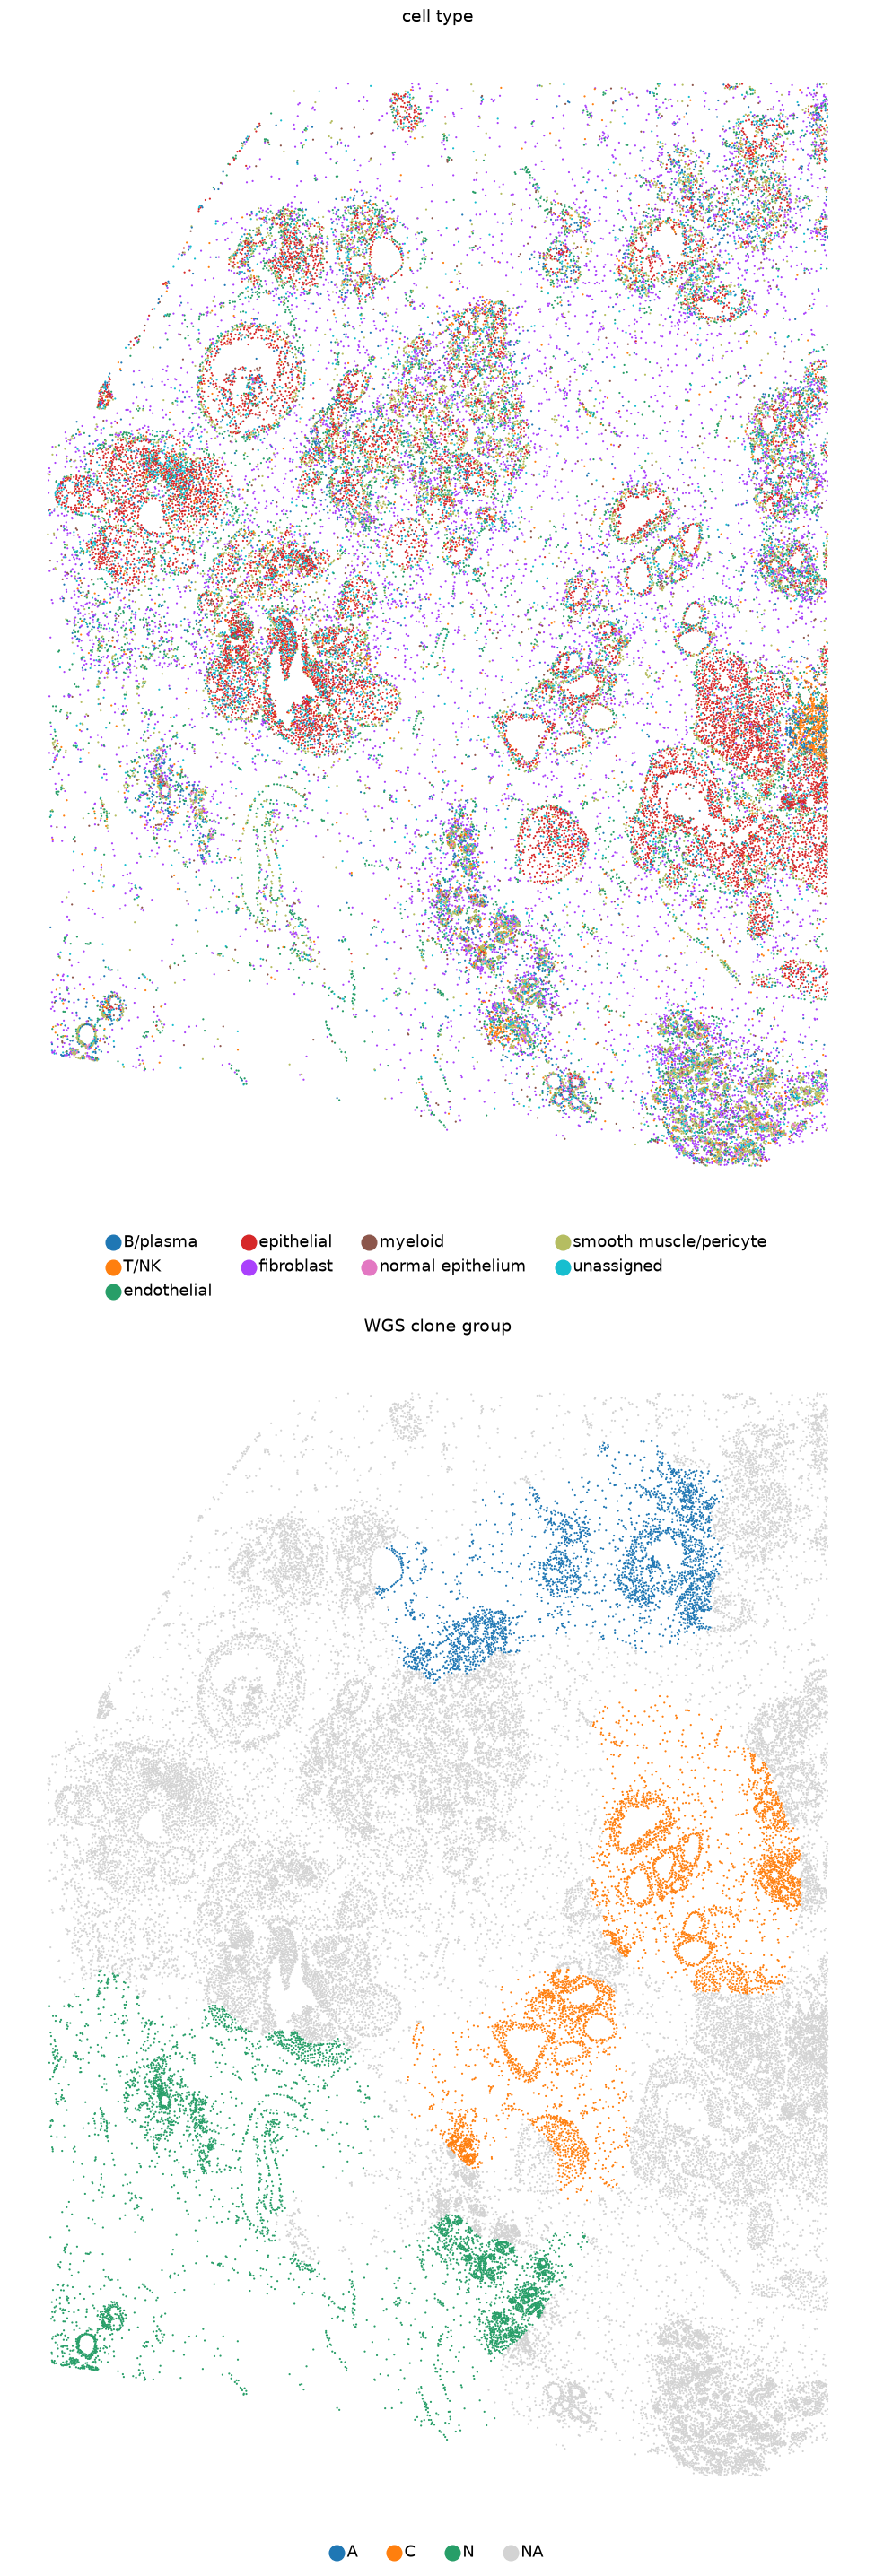

In [4]:
legend_below(
    cnv.pl.spatial_cnv(
        adata,
        color=["cell_type_ref", "wgs_clone_group"],
        size=10,
        ncols=1,
        hspace=0.1,
        title=["cell type", "WGS clone group"],
        show=False,
    )
)

The WGS table holds the log2 copy ratio of each chromosome arm per clone group. A and C share losses of 2q, 3p, 8p, 9p
and 17p and gains of 1q, 17q and 20q. They differ on other arms, e.g. 13q and 18q are lower in A, 5q and 11q are lower
in C, and 4q is higher in C. The table in `uns` also lists two focal amplicons of the preprint, 11q13 with CCND1 and
12q14 to 15, as rows of kind "focal". We leave them out, because we compare whole arms.

In [5]:
wgs = adata.uns["wgs_truth"]["arms"].query("kind == 'arm'")
wgs = wgs.pivot(index="arm", columns="clone_group", values="log2")
arms = sorted(wgs.index, key=lambda arm: (int(arm[:-1]), arm[-1]))
wgs = wgs.loc[arms]
print(f"arms in the WGS table: {len(arms)}")
focal = adata.uns["wgs_truth"]["arms"].query("kind == 'focal'")
print(focal.pivot(index="arm", columns="clone_group", values="log2").round(2).to_string(), end="\n\n")
wgs.round(2)

arms in the WGS table: 39
clone_group     A     C     N
arm                          
11q13_CCND1 -0.10  0.93  0.14
12q14-15     1.44  1.47  0.03



clone_group,A,C,N
arm,,,
1p,-0.10,-0.05,0.06
1q,0.15,0.29,0.23
2p,0.06,0.11,0.02
2q,-0.36,-0.28,-0.03
3p,-0.49,-0.59,-0.05
3q,0.05,0.12,-0.07
4p,0.08,0.11,-0.09
4q,-0.03,0.24,-0.08
5p,0.19,0.12,-0.08


## Copy number without and with a reference

{func}`infercnvpy.tl.copy_number` is not a port of R inferCNV. {func}`infercnvpy.tl.infercnv` follows R inferCNV and
smooths log expression along the genome relative to a reference, while `tl.copy_number` fits a count model to the raw
counts and returns per-cell calls, clones and segments. First, `tl.copy_number` groups the cells into expression types
with k-means, so that differences between cell types are not taken for copy number. Second, it finds the diploid
baseline, the expected expression of a cell without copy number changes. Reference cells are cells known to be normal,
and with a reference they define the baseline. Without a reference, the baseline comes from the expression types that
are flattest along the genome and from types that express known immune and stromal markers (the default
`normal_markers`, which `normal_markers=None` turns off). The run without a reference therefore still uses prior
knowledge, and after the runs, a cell prints how each run found its baseline. Here "diploid" means a profile like the
baseline, and "aneuploid" means a cell in a clone with changed arms. A tumor that doubled its whole genome without other
changes would be called diploid.

We run it three times:

1. without reference cells,
2. with immune cells, endothelial cells and fibroblasts as the reference, a common choice,
3. with all normal types, i.e. with smooth muscle cells and pericytes and the normal epithelium added.

{cite:t}`Wu2026` ran `tl.infercnv` of infercnvpy 0.6.1 with another reference (printed below, from their demo script),
so their setup differs from both references here. The unassigned cells are in no reference, because we don't know what
they are.

Each run writes its results under its own `key_added`, e.g. for `key_added="cn_none"`:

- the call of each cell to `obs["cn_none"]` and its clone to `obs["cn_none_clone"]`,
- the share of restarts that agree with its call to `obs["cn_none_stability"]`,
- the share of its counts that the pooled expression of the aneuploid cells explains best (0 to 1) to
  `obs["cn_none_spillover"]`,
- the copy number log ratios of each cell in genomic bins to `obsm["X_cn_none"]`, and the clones and their profiles to
  `uns["cn_none"]`.

With `calculate_gene_values=True`, a run also stores a log ratio per gene and cell. It is the mix of the clones' segment
means, weighted by the cell's clone probabilities, so it shows the clone profiles and not the noise of each cell. We
average it per arm over the epithelium of each clone group without the normal epithelium. The result is a pseudobulk
profile, which we correlate with the WGS. The arm assignment, printed with the runs below, finds 40 arms on the
autosomes, the smallest of them 21p with a single gene. We compare the 39 arms of the WGS table, which leaves out the p
arms of the acrocentric chromosomes 13, 14, 15, 21 and 22, and chrX. The gene values are a dense matrix of cells by
genes (printed size below), so `arm_profiles` removes them once it has used them.

In [6]:
# the setup of Wu et al. 2026, from their demo script
pd.Series(
    {
        "infercnvpy": "0.6.1",
        "function": "tl.infercnv",
        "reference": "Normal Luminal, Ductal Luminal",
        "chromosomes": "autosomes",
        "genes": 17237,
        "window_size": 100,
        "step": 10,
        "windows": 1516,
    },
    name="Wu et al. 2026",
)

infercnvpy                              0.6.1
function                          tl.infercnv
reference      Normal Luminal, Ductal Luminal
chromosomes                         autosomes
genes                                   17237
window_size                               100
step                                       10
windows                                  1516
Name: Wu et al. 2026, dtype: object

In [7]:
# GRCh38 centromere midpoints (Mb), to assign each gene to an arm
centromere_mb = {
    "chr1": 123.4, "chr2": 93.9, "chr3": 90.9, "chr4": 50.0, "chr5": 48.8, "chr6": 59.8, "chr7": 60.1, "chr8": 45.2,
    "chr9": 43.0, "chr10": 39.8, "chr11": 53.4, "chr12": 35.5, "chr13": 17.7, "chr14": 17.2, "chr15": 19.0,
    "chr16": 36.8, "chr17": 25.1, "chr18": 18.5, "chr19": 26.2, "chr20": 28.1, "chr21": 12.0, "chr22": 15.0,
}  # fmt: skip
chromosome = adata.var["chromosome"].astype(str)
side = np.where(adata.var["start"] / 1e6 < chromosome.map(centromere_mb), "p", "q")
gene_arm = pd.Series(chromosome.str.removeprefix("chr") + side, index=adata.var_names).where(
    chromosome.isin(centromere_mb)
)
genes_per_arm = gene_arm.value_counts()
print(
    f"arms: {len(genes_per_arm)}, genes per arm: {genes_per_arm.min()} ({genes_per_arm.idxmin()}) to {genes_per_arm.max()}"
)


def arm_profiles(key):
    """Mean gene value per arm of the epithelium of each clone group (without normal epithelium).

    Removes the gene values layer, a dense cells x genes array.
    """
    gene_values = adata.layers.pop(f"gene_values_{key}")
    print(f"{key}: gene values {gene_values.nbytes / 1e9:.1f} GB")
    used = adata.uns[key]["genes"].index
    columns = adata.var_names.get_indexer(used)
    profiles = {}
    for group in ["A", "C", "N"]:
        cells = (adata.obs["group"] == f"epithelium in {group}").to_numpy()
        gene_mean = pd.Series(np.nanmean(gene_values[np.ix_(cells, columns)], axis=0), index=used)
        profiles[group] = gene_mean.groupby(gene_arm[used]).mean()
    return pd.DataFrame(profiles).loc[arms]


def wgs_correlation(profile, wgs=wgs):
    """Pearson r over the arms between the pseudobulk profiles and the WGS, per clone group and for A minus C."""
    r = {f"r {group}": np.corrcoef(profile[group], wgs[group])[0, 1] for group in ["A", "C"]}
    r["r A-C"] = np.corrcoef(profile["A"] - profile["C"], wgs["A"] - wgs["C"])[0, 1]
    return r


immune_stromal = ["T/NK", "B/plasma", "myeloid", "endothelial", "fibroblast"]
all_normal = [*immune_stromal, "smooth muscle/pericyte", "normal epithelium"]
runs = {
    "no reference": {},
    "immune, endothelial, fibroblast": {"reference_key": "cell_type_ref", "reference_cat": immune_stromal},
    "all normal types": {"reference_key": "cell_type_ref", "reference_cat": all_normal},
}
keys = dict(zip(runs, ["cn_none", "cn_immune_stromal", "cn_all_normal"], strict=True))
profiles, correlations = {}, {}
for name, kwargs in runs.items():
    start = time.perf_counter()
    cnv.tl.copy_number(adata, calculate_gene_values=True, key_added=keys[name], show_progress=False, **kwargs)
    print(f"{name}: {time.perf_counter() - start:.0f} s")
    profiles[name] = arm_profiles(keys[name])
    correlations[name] = wgs_correlation(profiles[name])

arms: 40, genes per arm: 1 (21p) to 981


no reference: 83 s
cn_none: gene values 3.2 GB


immune, endothelial, fibroblast: 140 s
cn_immune_stromal: gene values 3.2 GB


all normal types: 54 s
cn_all_normal: gene values 3.2 GB


In [8]:
order = [
    "T/NK", "B/plasma", "myeloid", "endothelial", "fibroblast", "smooth muscle/pericyte", "unassigned",
    "normal epithelium", "epithelium in A", "epithelium in C", "epithelium in N", "other epithelium",
]  # fmt: skip
aneuploid = pd.DataFrame(
    {name: (adata.obs[key] == "aneuploid").groupby(adata.obs["group"]).mean() for name, key in keys.items()}
).loc[order]
aneuploid.insert(0, "cells", adata.obs["group"].value_counts())
for name, key in keys.items():
    print(f"{name}: baseline from {adata.uns[key]['seed']['method']}")
aneuploid.round(3)

no reference: baseline from flat groups + markers
immune, endothelial, fibroblast: baseline from reference
all normal types: baseline from reference


,cells,no reference,"immune, endothelial, fibroblast",all normal types
group,,,,
T/NK,2121,0.235,0.005,0.003
B/plasma,3631,0.412,0.013,0.008
myeloid,1761,0.222,0.010,0.005
endothelial,5480,0.168,0.004,0.003
fibroblast,8594,0.049,0.002,0.001
smooth muscle/pericyte,7024,0.374,0.285,0.003
unassigned,4887,0.555,0.519,0.500
normal epithelium,762,0.042,0.010,0.000
epithelium in A,425,0.918,0.868,0.840


The table gives the share of cells that each run calls aneuploid, per group. Without a reference, `tl.copy_number` calls
most of the epithelium of A and C aneuploid (91.8% and 95.0%), and also 16.8% to 41.2% of the immune and endothelial
cells and 37.4% of the smooth muscle cells and pericytes. Fibroblasts (4.9%) and the normal epithelium (4.2%) are mostly
diploid. With the immune, endothelial and fibroblast reference, the reference types drop to 1.3% or less, while the
smooth muscle cells and pericytes stay at 28.5% (see the next section). With all normal types in the reference, every
normal type is at 0.8% or less, and the epithelium of A and C stays mostly aneuploid (84.0% and 90.1%).

The low rates of the reference types are close to 0 by construction. Reference cells stay in the diploid clone while the
clones are fitted, and their types get a diploid prior. They don't measure false calls. Types outside the reference are
a fairer check, e.g. the normal epithelium in the run with the smaller reference (1.0%). B/plasma cells have the highest
rate of the immune types without a reference (41.2%). Segmentation can merge plasma cells with tumor cells next to them.
Plasma cells also express the immunoglobulin loci on 2p, 14q and 22q at very high levels, which can look like gains.

Two groups have no clear answer. Every run calls 50.0% to 55.5% of the unassigned cells aneuploid. They fall into the
same clones as the tumor epithelium (table further below), so many of them are likely tumor cells without a confident
type. Every run also calls 74.0% to 75.7% of the epithelium in group N aneuploid, although the WGS of N shows few
changes (WGS table above).

In [9]:
# 95% intervals of r from 1,000 bootstrap samples of the 39 arms
rng = np.random.default_rng(0)
samples = [rng.choice(len(arms), len(arms)) for _ in range(1000)]
table, boot = {}, {}
for name, profile in profiles.items():
    rows = []
    for i in samples:
        p, w = profile.iloc[i], wgs.iloc[i]
        rows.append(wgs_correlation(p, w))
    boot[name] = pd.DataFrame(rows)
    low, high = boot[name].quantile([0.025, 0.975]).to_numpy()
    r = correlations[name].items()
    table[name] = {k: f"{v:.2f} ({lo:.2f} to {hi:.2f})" for (k, v), lo, hi in zip(r, low, high, strict=True)}
# paired: the difference to the run without a reference, on the same bootstrap samples
for name in ["immune, endothelial, fibroblast", "all normal types"]:
    diff = boot[name] - boot["no reference"]
    low, high = diff.quantile([0.025, 0.975]).to_numpy()
    table[f"{name} minus no reference"] = {
        k: f"{correlations[name][k] - correlations['no reference'][k]:+.2f} ({lo:+.2f} to {hi:+.2f})"
        for k, lo, hi in zip(diff.columns, low, high, strict=True)
    }
pd.DataFrame(table).T

,r A,r C,r A-C
no reference,0.81 (0.66 to 0.88),0.82 (0.64 to 0.90),0.84 (0.78 to 0.92)
"immune, endothelial, fibroblast",0.74 (0.55 to 0.85),0.82 (0.65 to 0.90),0.88 (0.80 to 0.93)
all normal types,0.73 (0.54 to 0.84),0.81 (0.64 to 0.89),0.88 (0.82 to 0.93)
"immune, endothelial, fibroblast minus no reference",-0.07 (-0.13 to -0.01),+0.00 (-0.04 to +0.05),+0.03 (-0.03 to +0.07)
all normal types minus no reference,-0.08 (-0.15 to -0.02),-0.00 (-0.05 to +0.04),+0.04 (-0.02 to +0.07)


Against the WGS, the three runs reach a Pearson r of 0.73 to 0.81 for A and 0.81 to 0.82 for C. The difference A minus C
tests whether the profiles separate the two clone groups, and its r is 0.84 to 0.88. The intervals in parentheses come
from a bootstrap over the arms. The last two rows compare each reference run with the run without a reference on the
same bootstrap samples. Both references lower r for A, by 0.07 and 0.08, with intervals that end just below 0 (-0.13 to
-0.01 and -0.15 to -0.02). They leave r for C unchanged. For A minus C, they raise r by 0.03 and 0.04, with intervals
that include 0. Arms of one chromosome often change together, so the arms are not independent and the intervals are too
narrow. The drop for A may therefore be within the noise. The reference changes the calls of the normal cells much more
than the tumor profiles.

A high r of one group is a weak check on its own, because A and C share many changes. The next table correlates each
pseudobulk with each WGS profile, for the run with all normal types.

In [10]:
# each pseudobulk against each WGS profile, for the run with all normal types
profile = profiles["all normal types"]
pd.DataFrame(
    {f"WGS {w}": {f"pseudobulk {p}": np.corrcoef(profile[p], wgs[w])[0, 1] for p in "ACN"} for w in "ACN"}
).round(2)

,WGS A,WGS C,WGS N
pseudobulk A,0.73,0.38,0.23
pseudobulk C,0.75,0.81,0.34
pseudobulk N,0.66,0.44,0.37


The pseudobulk of A matches the WGS of A (0.73) much better than that of C (0.38). The pseudobulk of C matches the WGS
of C (0.81), but nearly as well that of A (0.75). Only the difference A minus C shows that the C profile is specific.
The pseudobulk of N correlates best with the WGS of A (0.66) and only weakly with the nearly flat WGS of N (0.37). The N
regions on the section and the dissected N regions may hold different cells, because the WGS comes from consecutive
sections and the outlines are approximate.

The plot shows the pseudobulk of the run with all normal types against the WGS. It labels the arms that differ from 0 by
more than 0.3 in the WGS, and the 3 arms farthest from a straight-line fit. The pseudobulk is on another scale than the
WGS, because it averages the clone profiles over the cells of a group. The cells in N0 add gene values of 0 by
construction, and the clones that lack a change add values near 0. In the plot, the gains of the WGS lie in a narrow
band near 0, while the losses spread down to about -0.4. The correlation therefore rests mainly on the losses.
Chromosome 18 disagrees most. The pseudobulk of A loses 18q more deeply than its WGS, and it loses 18p, where the WGS of
A shows a small gain.

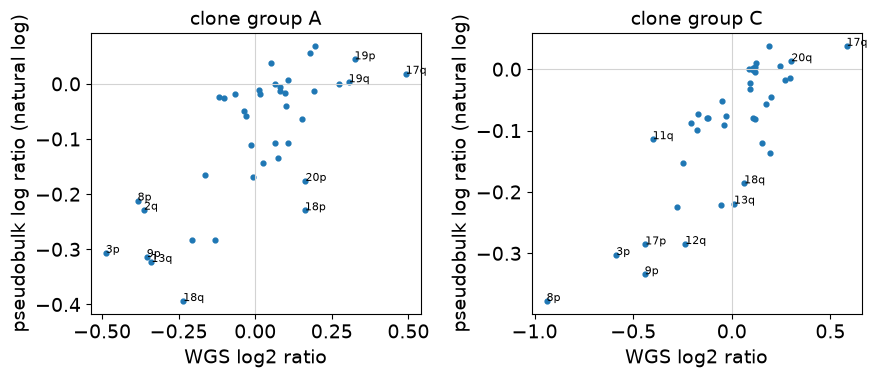

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, group in zip(axes, ["A", "C"], strict=True):
    profile = profiles["all normal types"][group]
    ax.axhline(0, color="lightgray", lw=0.8)
    ax.axvline(0, color="lightgray", lw=0.8)
    ax.scatter(wgs[group], profile, s=12)
    # label the arms with large WGS changes and the 3 arms farthest from a straight-line fit
    slope, intercept = np.polyfit(wgs[group], profile, 1)
    residual = (profile - (slope * wgs[group] + intercept)).abs()
    for arm in arms:
        if abs(wgs.loc[arm, group]) > 0.3 or arm in residual.nlargest(3).index:
            ax.annotate(arm, (wgs.loc[arm, group], profile[arm]), fontsize=8)
    ax.set(xlabel="WGS log2 ratio", ylabel="pseudobulk log ratio (natural log)", title=f"clone group {group}")
    ax.grid(False)
plt.tight_layout()

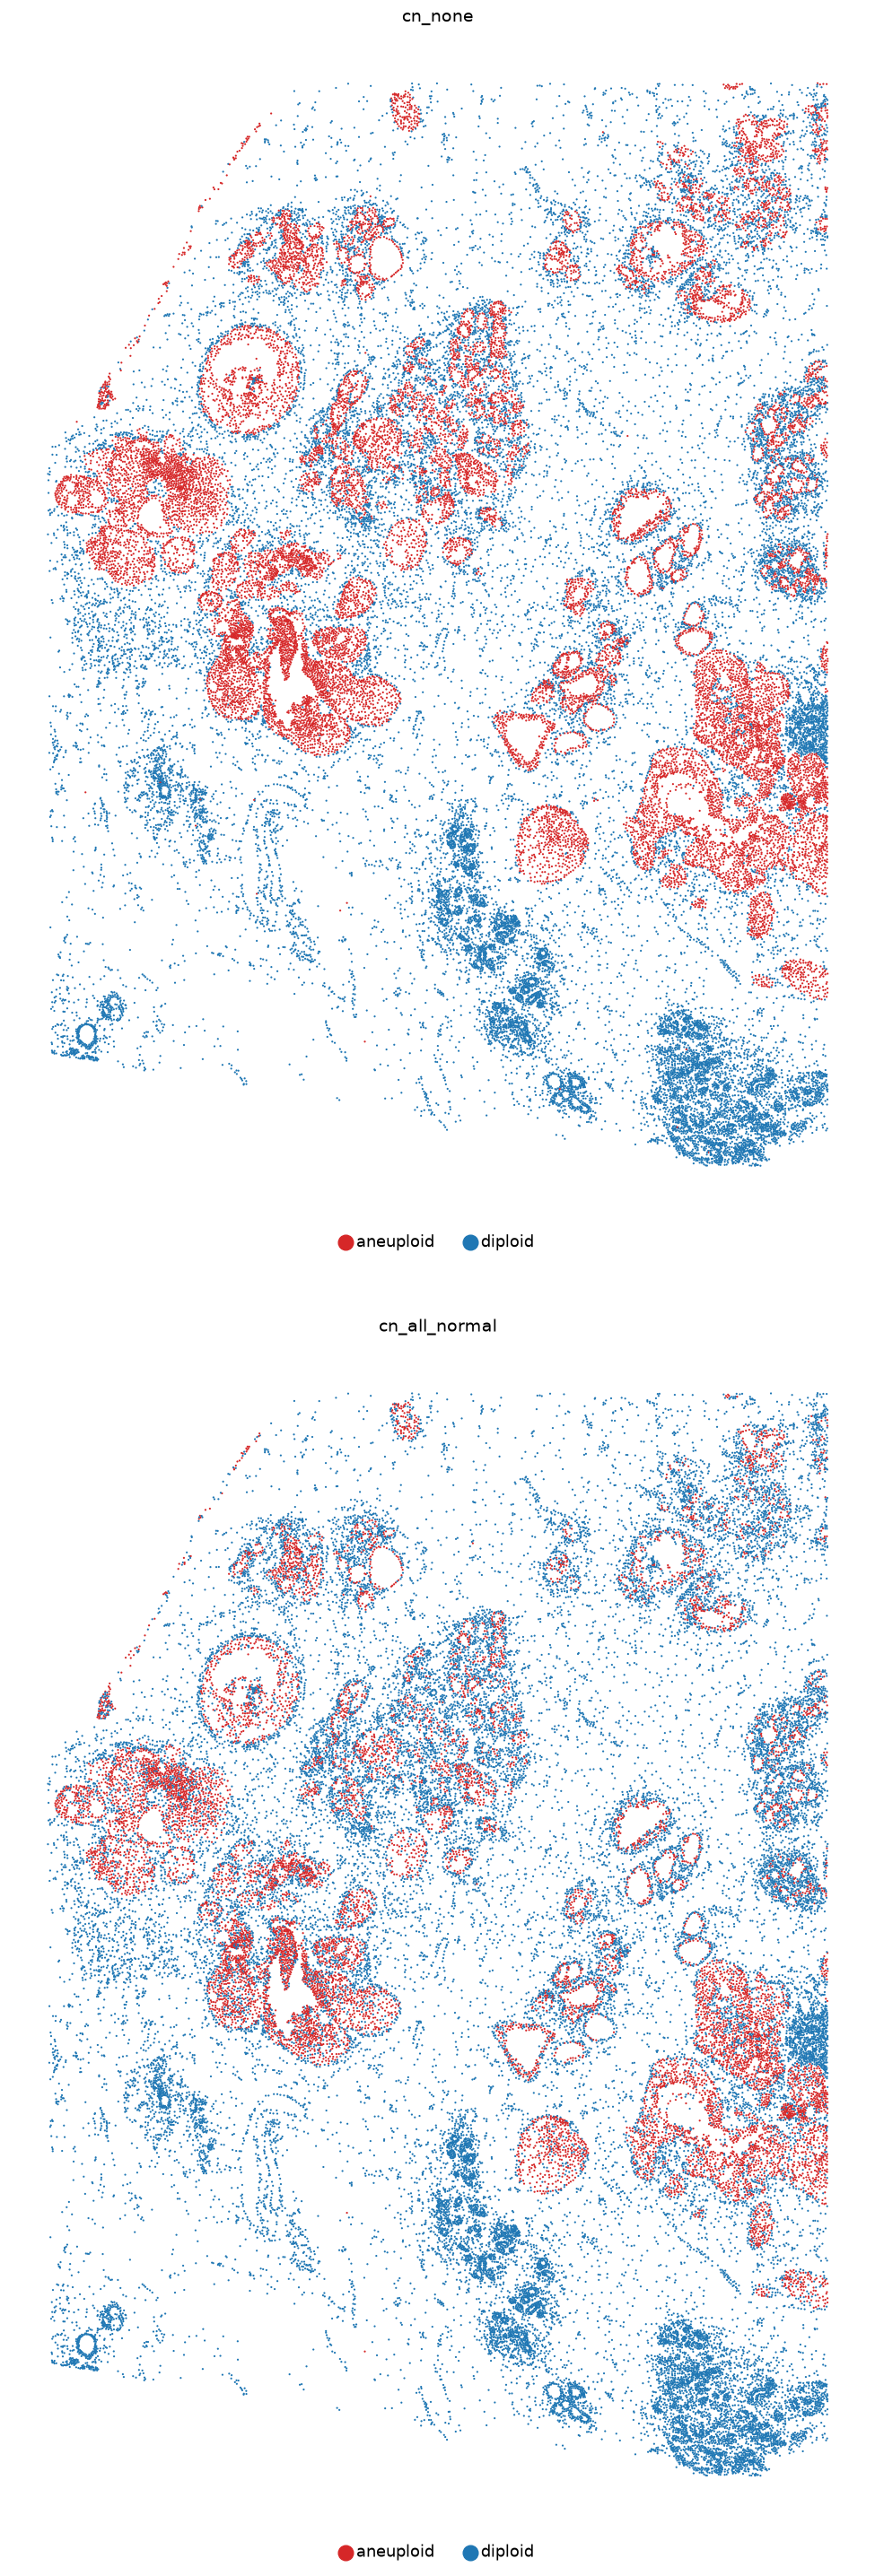

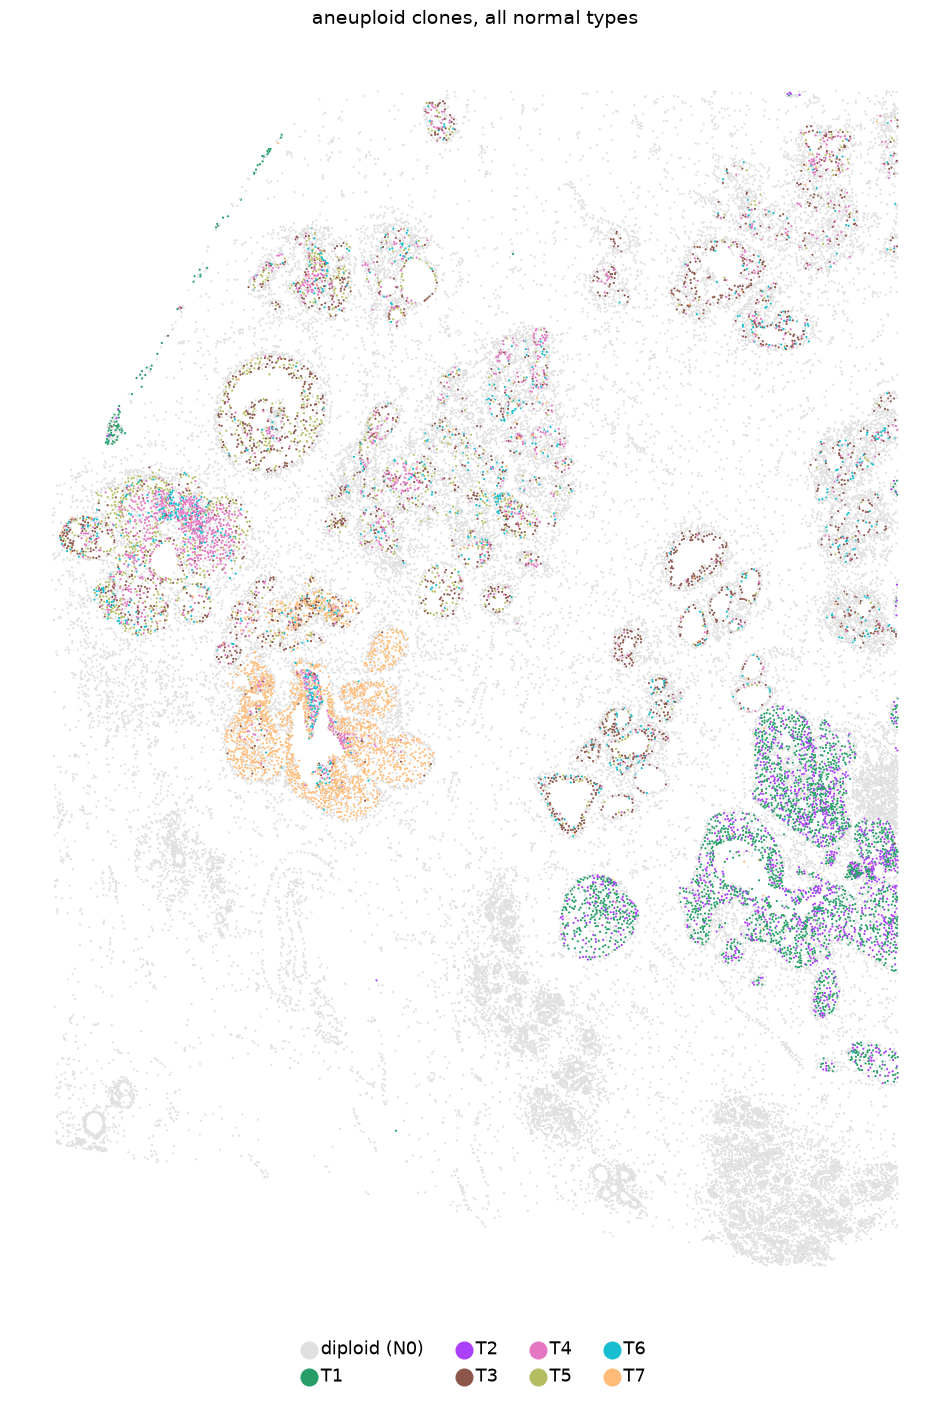

In [12]:
# aneuploid red, diploid and the diploid clone N0 blue
for key in ["cn_none", "cn_immune_stromal", "cn_all_normal", "cn_all_normal_clone"]:
    adata.obs[key] = adata.obs[key].cat.remove_unused_categories()
    palette = [c for c in sc.pl.palettes.default_20 if c not in ("#d62728", "#1f77b4", "#ff9896", "#aec7e8")]
    colors = dict(zip(adata.obs[key].cat.categories, palette, strict=False))
    colors.update({"aneuploid": "#d62728", "diploid": "#1f77b4", "N0": "#1f77b4"})
    adata.uns[f"{key}_colors"] = [colors[c] for c in adata.obs[key].cat.categories]
legend_below(cnv.pl.spatial_cnv(adata, color=["cn_none", "cn_all_normal"], size=10, ncols=1, hspace=0.1, show=False))
# the aneuploid clones on their own, with the diploid cells in gray
clone = adata.obs["cn_all_normal_clone"]
adata.obs["aneuploid clone"] = clone.cat.rename_categories({"N0": "diploid (N0)"})
colors = dict(zip(clone.cat.categories, adata.uns["cn_all_normal_clone_colors"], strict=True))
colors["diploid (N0)"] = "#e0e0e0"
adata.uns["aneuploid clone_colors"] = [colors[c] for c in adata.obs["aneuploid clone"].cat.categories]
legend_below(
    cnv.pl.spatial_cnv(adata, color="aneuploid clone", size=10, title="aneuploid clones, all normal types", show=False)
)

On the tissue, both runs call the ducts aneuploid and most of the stroma diploid, and the run without a reference calls
more scattered cells in the stroma aneuploid. `tl.copy_number` names the diploid clone N0 and the aneuploid clones T1,
T2 and so on, and N0 has nothing to do with clone group N. The second map shows the aneuploid clones alone. Most ducts
mix several clones, and T7 fills a large duct at the middle left, at the upper edge of the left N region. The table
counts the epithelial and unassigned cells per clone of the run with all normal types.

In [13]:
pd.crosstab(adata.obs["group"], adata.obs["cn_all_normal_clone"]).loc[
    ["epithelium in A", "epithelium in C", "epithelium in N", "other epithelium", "unassigned"]
]

cn_all_normal_clone,N0,T1,T2,T3,T4,T5,T6,T7
group,,,,,,,,
epithelium in A,68,0,0,177,98,28,51,3
epithelium in C,93,228,110,343,31,45,90,2
epithelium in N,45,0,0,3,1,0,2,126
other epithelium,510,1649,952,1118,1032,907,499,1229
unassigned,2443,334,157,545,427,159,303,519


The clone groups fall into different clones only in part. The epithelium of A is mostly in T3 (177 cells) and T4 (98),
that of C in T3 (343), T1 (228) and T2 (110), and that of N in T7 (126). T1 and T2 hold C but no A, T4 holds more A than
C, and A and C share T3. Most of the epithelium of N falls into T7, which holds few cells of A or C but many cells
outside the regions. T7 shares the losses of 2q and 3p with the clones of A and C. The WGS of N doesn't show these
losses (WGS table above), so the WGS doesn't confirm the profile of the N cells in T7. The dissected N regions of the
consecutive sections may have missed these tumor cells, or the placement of the outline may be off. The diploid clone N0
holds 68 cells of A and 93 of C. They may be normal cells without a normal state label, or tumor cells whose calls are
too weak. Most of the epithelial cells in the clones lie outside the dissected regions ("other epithelium").

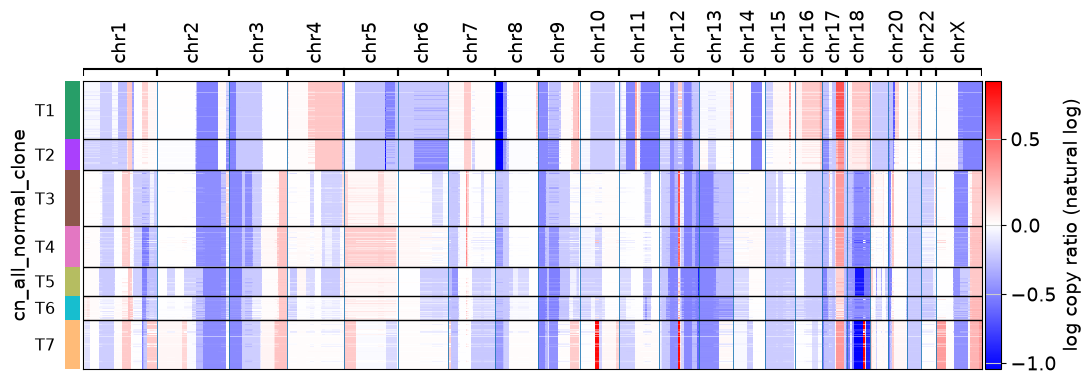

,n_cells,aneuploid,amplitude,burden
N0,32439,False,0.014,0.000
T1,2240,True,0.223,0.579
T2,1223,True,0.201,0.577
T3,2186,True,0.173,0.440
T4,1591,True,0.198,0.457
T5,1140,True,0.178,0.587
T6,947,True,0.164,0.541
T7,1934,True,0.175,0.487


In [14]:
# the heatmap of the aneuploid clones only, since N0 holds most of the cells
aneuploid_cells = adata[adata.obs["cn_all_normal_clone"] != "N0"].copy()
aneuploid_cells.obs["cn_all_normal_clone"] = aneuploid_cells.obs["cn_all_normal_clone"].cat.remove_unused_categories()
aneuploid_cells.uns["cn_all_normal_clone_colors"] = [
    colors[c] for c in aneuploid_cells.obs["cn_all_normal_clone"].cat.categories
]
axes = cnv.pl.chromosome_heatmap(
    aneuploid_cells, groupby="cn_all_normal_clone", use_rep="cn_all_normal", figsize=(12, 4), show=False
)
axes["colorbar_ax"].set_ylabel("log copy ratio (natural log)")
plt.show()
adata.uns["cn_all_normal"]["clones"].round(3)

The heatmap shows the profiles of the aneuploid clones as natural log copy ratios, relative to the diploid baseline.
Most of them have losses on 2q, 3p and 9p, which A and C share in the WGS. T1 and T2, which hold C but no A, have a deep
loss of 8p. The 8p loss of C is the deepest arm change in the WGS table. Most clones gain 17q, as A and C do in the WGS.
T3 to T7 lose chromosome 18, deepest in T5 and T7, and T1 and T2 lose chrX. The tables below list short segments with
large changes, the losses on chromosome 18, and the gains in 12q14 to 15.

In the clones table, `burden` is the share of genes in long changed segments (0.44 to 0.59 for the aneuploid clones),
and `amplitude` is the size of the smooth profile. An aneuploid clone whose amplitude is too small merges into N0 (see
the docstring of {func}`~infercnvpy.tl.copy_number`). The clones are groups of cells that share a profile in the model,
and they are not proven subclones.

In [15]:
# short segments with large changes (fewer than 30 genes), and the losses on chromosome 18
segments = adata.uns["cn_all_normal"]["segments"]
columns = ["clone", "chromosome", "start", "end", "n_genes", "log_ratio", "ci_low", "ci_high"]
short = segments[(segments["n_genes"] < 30) & (segments["log_ratio"].abs() > 0.4)]
print(short[columns].sort_values("log_ratio").round(2).to_string(index=False), end="\n\n")
chr18 = segments[(segments["chromosome"] == "chr18") & (segments["log_ratio"] < -0.4)]
print(chr18[columns].round(2).to_string(index=False), end="\n\n")
# every gain on chromosome 12 between 57 and 77 Mb (12q14 to 15), without a cut on size or amplitude
chr12 = segments[
    (segments["chromosome"] == "chr12")
    & (segments["end"] > 57e6)
    & (segments["start"] < 77e6)
    & (segments["log_ratio"] > 0)
]
print(chr12[columns].round(2).to_string(index=False))

clone chromosome     start       end  n_genes  log_ratio  ci_low  ci_high
   T5      chr12 132986365 133214832        6      -0.94   -1.00    -0.87
   T7      chr18  67506587  80147523       19      -0.92   -0.97    -0.87
   T1      chr20  18137228  23086324       18      -0.67   -0.76    -0.59
   T7      chr12 128793194 133214832       21      -0.61   -0.65    -0.57
   T5      chr18  61808067  80147523       28      -0.57   -0.62    -0.52
   T7       chr1 200404940 204152044       28      -0.53   -0.57    -0.48
   T3      chr12 124324415 133214832       26      -0.50   -0.52    -0.48
   T7      chr18  20944612  24453531       16      -0.49   -0.54    -0.44
   T6      chr11  88265069  94876748       17      -0.49   -0.56    -0.41
   T4       chr9  35681992  70354873       28      -0.45   -0.48    -0.41
   T5      chr19  19710472  22010949       16      -0.43   -0.50    -0.37
   T1       chr4 185363872 189963202        9      -0.43   -0.48    -0.38
   T2      chr20  17941597  21246622  

The deepest losses on chromosome 18 reach about -1 in T7 and T5 (18q, natural log), deeper than the loss of one of two
copies (ln 0.5 = -0.69), while the WGS of 18q is -0.24 in A, 0.06 in C and -0.10 in N (log2). Expression is not copy
number, and the depth of a segment is not a copy number either. Read such a segment as a loss, and check it on DNA
before you call it a deep or homozygous loss.

The focal WGS rows printed with the WGS table put the 12q14 to 15 amplicon in A and C (log2 1.44 and 1.47) and not in N.
The last table lists every gain on chromosome 12 between 57 and 77 Mb, without a cut on size or depth. T3, the clone
that A and C share, and T4, mostly A, gain the same 34 genes at 63.8 to 70.0 Mb (natural log 0.56 and 0.49). The clones
of A and C therefore show the amplicon, although T1 and T2, the other clones of C, gain it only weakly or not at all.
T7, the clone of most of the N epithelium, gains the same segment more strongly (0.80), which the WGS of N doesn't show.
T7 also has short gains on chromosomes 10 and 18, with 17 to 19 genes each. A short segment can come from a cluster of
genes that are expressed together. Check it on DNA or by FISH before you call it an amplification.

## A normal type left out of the reference

The documentation of {func}`~infercnvpy.tl.copy_number` says that every normal cell type belongs in the reference. A
normal type left out of it can form clones from the smooth part of its expression difference to the reference, and
normal cells of other types can join those clones. The run with the immune, endothelial and fibroblast reference leaves
out the smooth muscle cells and pericytes and the normal epithelium. The table counts the cells of each group per clone
of that run.

In [16]:
pd.crosstab(adata.obs["group"], adata.obs["cn_immune_stromal_clone"], margins=True).loc[[*order, "All"]]

cn_immune_stromal_clone,N0,T1,T2,T3,T4,T5,T6,T7,All
group,,,,,,,,,
T/NK,2110,3,0,0,1,1,0,6,2121
B/plasma,3583,7,2,1,3,0,3,32,3631
myeloid,1743,4,0,1,6,2,0,5,1761
endothelial,5459,7,0,0,2,1,1,10,5480
fibroblast,8576,5,4,0,4,0,1,4,8594
smooth muscle/pericyte,5019,146,211,464,590,117,225,252,7024
unassigned,2353,295,200,607,288,158,489,497,4887
normal epithelium,754,0,0,0,8,0,0,0,762
epithelium in A,56,0,0,197,40,27,103,2,425


Smooth muscle cells and pericytes are called aneuploid at 28.5% in this run (table of the calls per group). They are in
every aneuploid clone, most of all in T4, where they are 590 of the 1,400 cells, next to the tumor epithelium of A and
C. With all normal types in the reference, 0.3% of them are called aneuploid. The normal epithelium doesn't show the
pitfall here. Left out of the reference, 1.0% of it is called aneuploid, and 8 of its 762 cells are in an aneuploid
clone.

In DCIS, part of the cells typed as smooth muscle may be myoepithelial cells, which ring the ducts. Segmentation at the
duct wall can also mix tumor transcripts into them. The map and the table below check that for this run.

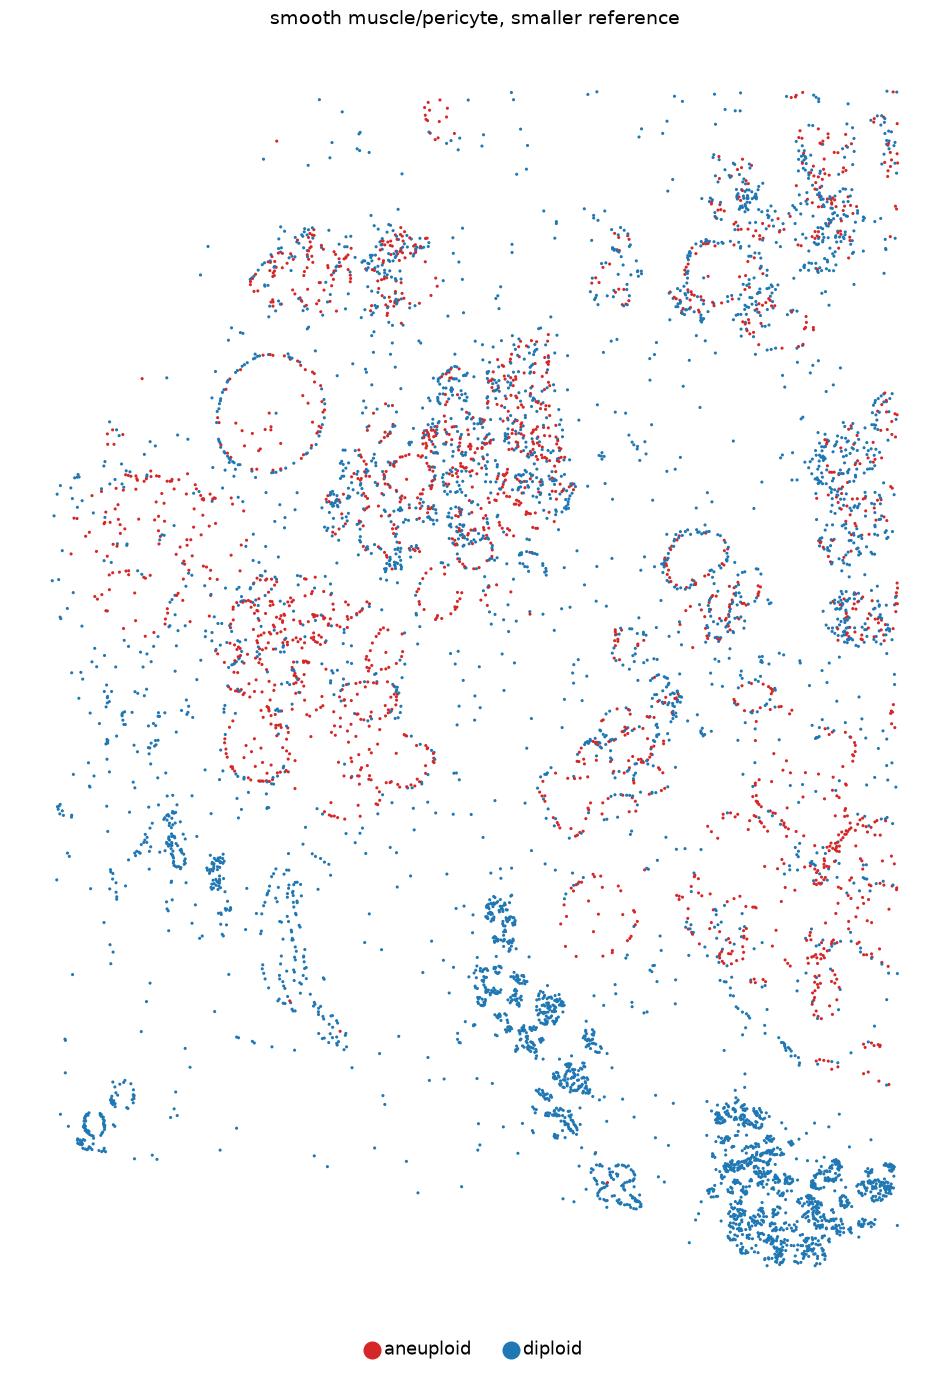

,ACTA2,MYH11,RGS5,KRT14,KRT5,TP63,KRT8,KRT18,median distance to epithelium (um)
cn_immune_stromal,,,,,,,,,
aneuploid,0.27,0.27,0.15,0.02,0.21,0.27,0.16,0.33,11.70
diploid,0.29,0.23,0.14,0.04,0.26,0.40,0.13,0.22,36.49


In [17]:
# where the smooth muscle cells and pericytes lie, and how they differ by call
smooth_muscle = adata[adata.obs["cell_type_ref"] == "smooth muscle/pericyte"]
legend_below(
    cnv.pl.spatial_cnv(
        smooth_muscle, color="cn_immune_stromal", size=20, title="smooth muscle/pericyte, smaller reference", show=False
    )
)
markers = [g for g in ["ACTA2", "MYH11", "RGS5", "KRT14", "KRT5", "TP63", "KRT8", "KRT18"] if g in adata.var_names]
detected = (
    pd.DataFrame((smooth_muscle[:, markers].X > 0).toarray(), columns=markers, index=smooth_muscle.obs_names)
    .groupby(smooth_muscle.obs["cn_immune_stromal"], observed=True)
    .mean()
)
# distance to the nearest epithelial cell that isn't normal epithelium, independent of the model
tree = cKDTree(adata.obsm["spatial"][other_epithelium.to_numpy()])
distance = pd.Series(tree.query(smooth_muscle.obsm["spatial"])[0], index=smooth_muscle.obs_names)
detected["median distance to epithelium (um)"] = distance.groupby(smooth_muscle.obs["cn_immune_stromal"]).median()
detected.round(2)

The smooth muscle cells and pericytes called aneuploid lie in rings around the ducts, closer to the tumor epithelium
(median 11.7 µm) than the diploid ones (36.5 µm), which lie mostly in the stroma. The two detect the smooth muscle
markers ACTA2 and MYH11 about equally often, and the aneuploid ones don't detect the basal keratins KRT14 and KRT5 or
TP63 of myoepithelial cells more often. They detect the luminal keratins KRT8 and KRT18 a little more often (0.16 and
0.33 against 0.13 and 0.22). Cells at the duct wall can pick up tumor transcripts in the segmentation. Part of their
calls may come from that and part from the pitfall above, and these data don't separate the two. With all normal types
in the reference, the cells are called diploid in either case.

In [18]:
# the same two references with another k-means seed
# with inplace=False, copy_number returns (obs columns, X_copy_number, uns, gene values)
seed_1 = {
    name: cnv.tl.copy_number(adata, random_state=1, inplace=False, show_progress=False, **runs[name])[0]
    for name in ["immune, endothelial, fibroblast", "all normal types"]
}
clones_1 = pd.crosstab(adata.obs["group"], seed_1["immune, endothelial, fibroblast"]["copy_number_clone"], margins=True)
print(clones_1.loc[["smooth muscle/pericyte", "normal epithelium", "All"]].to_string())
print()
pd.DataFrame(
    {name: (obs["copy_number"] == "aneuploid").groupby(adata.obs["group"]).mean() for name, obs in seed_1.items()}
).loc[order].round(3)

copy_number_clone          N0    T1    T2    T3    T4   T5    T6    T7    All
group                                                                        
smooth muscle/pericyte   4863   712   100   272   547  139   124   267   7024
normal epithelium         749    12     0     1     0    0     0     0    762
All                     29905  1282  1628  2275  3800  924  1496  2390  43700



,"immune, endothelial, fibroblast",all normal types
group,,
T/NK,0.008,0.001
B/plasma,0.013,0.006
myeloid,0.012,0.002
endothelial,0.007,0.002
fibroblast,0.003,0.001
smooth muscle/pericyte,0.308,0.002
unassigned,0.524,0.509
normal epithelium,0.017,0.000
epithelium in A,0.880,0.852


With seed 1, 30.8% of the smooth muscle cells and pericytes are called aneuploid with the smaller reference, and 0.2%
with all normal types. Here they are 712 of the 1,282 cells of clone T1, more than half of it. The normal epithelium is
called aneuploid at 1.7% and 0%, and 13 of its cells are in aneuploid clones. Put every normal type into the reference.
When a run calls many cells of a known normal type aneuploid, check whether that type is in the reference before you
read the calls as copy number.

## Restarts

The k-means step starts from a random seed, so the expression types, and with them the clones and calls, can change with
the seed. By default, `tl.copy_number` fits 5 times, each with its own seed, and keeps the fit whose calls agree most
with those of the other fits. Without a reference, we compare three runs with 5 restarts (`random_state` 0, 1 and 2)
with three single fits (`n_restarts=1`) at `random_state` 3, 4 and 5. The single fits use other seeds, because the first
of the 5 fits at a seed is the single fit at that seed. The fits are compared by the share of cells with the same call,
by the Jaccard index of their aneuploid cells (the cells that both call aneuploid over the cells that either calls
aneuploid), and by the adjusted Rand index (ARI) of the clones over the cells that both call aneuploid. The ARI is 1 for
the same partition and about 0 for unrelated ones.

In [19]:
# calls and clones of each fit, as strings, because the categories differ between fits
fits, n_clones = {}, {}
fits["5 restarts, seed 0"] = adata.obs[["cn_none", "cn_none_clone"]].set_axis(["call", "clone"], axis=1).astype(str)
n_clones["5 restarts, seed 0"] = adata.uns["cn_none"]["clones"]["aneuploid"].sum()
# single fits at seeds 3 to 5, because the single fit at seed s is the first fit of the 5 restarts at seed s
for n_restarts, seeds in [(5, [1, 2]), (1, [3, 4, 5])]:
    for seed in seeds:
        name = f"{n_restarts} restart{'s' * (n_restarts > 1)}, seed {seed}"
        obs, _, uns, _ = cnv.tl.copy_number(
            adata, n_restarts=n_restarts, random_state=seed, inplace=False, show_progress=False
        )
        fits[name] = obs[["copy_number", "copy_number_clone"]].set_axis(["call", "clone"], axis=1).astype(str)
        n_clones[name] = uns["clones"]["aneuploid"].sum()
aneuploid_sets = {name: (fit["call"] == "aneuploid").to_numpy() for name, fit in fits.items()}


def clone_ari(a, b):
    """Adjusted Rand index of the clones over the cells that both fits call aneuploid."""
    both = aneuploid_sets[a] & aneuploid_sets[b]
    return adjusted_rand_score(fits[a]["clone"][both], fits[b]["clone"][both])


same_call = pd.DataFrame({a: {b: (fits[a]["call"] == fits[b]["call"]).mean() for b in fits} for a in fits})
jaccard = pd.DataFrame(
    {a: {b: (sa & sb).sum() / (sa | sb).sum() for b, sb in aneuploid_sets.items()} for a, sa in aneuploid_sets.items()}
)
ari = pd.DataFrame({a: {b: clone_ari(a, b) for b in fits} for a in fits})
print("share of cells with the same call\n", same_call.round(3).to_string(), sep="")
print("\nJaccard index of the aneuploid cells\n", jaccard.round(3).to_string(), sep="")
print(
    "\nadjusted Rand index of the clones, over the cells that both fits call aneuploid\n",
    ari.round(2).to_string(),
    sep="",
)
pd.DataFrame({"aneuploid cells": {k: s.sum() for k, s in aneuploid_sets.items()}, "aneuploid clones": n_clones})

share of cells with the same call
                    5 restarts, seed 0  5 restarts, seed 1  5 restarts, seed 2  1 restart, seed 3  1 restart, seed 4  1 restart, seed 5
5 restarts, seed 0               1.000               0.989               0.991              0.989              0.928              0.984
5 restarts, seed 1               0.989               1.000               0.994              0.992              0.929              0.988
5 restarts, seed 2               0.991               0.994               1.000              0.993              0.927              0.986
1 restart, seed 3                0.989               0.992               0.993              1.000              0.927              0.987
1 restart, seed 4                0.928               0.929               0.927              0.927              1.000              0.927
1 restart, seed 5                0.984               0.988               0.986              0.987              0.927              1.000

Jaccard index

,aneuploid cells,aneuploid clones
"5 restarts, seed 0",18191,11
"5 restarts, seed 1",17877,10
"5 restarts, seed 2",17998,12
"1 restart, seed 3",17893,10
"1 restart, seed 4",20442,12
"1 restart, seed 5",17534,9


In [20]:
# mean over the pairs of fits with the same number of restarts
pairs = {
    n: [(a, b) for a in fits for b in fits if a < b and a.startswith(n) and b.startswith(n)]
    for n in ["5 restarts", "1 restart"]
}
pd.DataFrame(
    {
        n: {
            "same call": np.mean([same_call.loc[a, b] for a, b in p]),
            "Jaccard": np.mean([jaccard.loc[a, b] for a, b in p]),
            "clone ARI": np.mean([ari.loc[a, b] for a, b in p]),
        }
        for n, p in pairs.items()
    }
).round(3)

,5 restarts,1 restart
same call,0.992,0.947
Jaccard,0.980,0.887
clone ARI,0.595,0.478


The calls depend less on the seed with restarts. Between pairs of runs with 5 restarts, 99.2% of the cells get the same
call on average, and the Jaccard index of the aneuploid cells is 0.980, against 94.7% and 0.887 between single fits. The
single fit at seed 4 differs most, with 20,442 aneuploid cells and a Jaccard index of 0.844 to 0.850 to the other fits.
The clones are much less stable than the calls. Over the cells that both fits call aneuploid, the ARI of the clones is
0.56 to 0.67 between runs with 5 restarts (mean 0.595) and 0.44 to 0.51 between single fits (mean 0.478), and the runs
find 9 to 12 aneuploid clones. With three pairs each, the gain in clone ARI from the restarts is a rough estimate. Read
the clones as a summary of the profiles in the tumor, and not as a fixed partition of its cells.

fit kept: 4, aneuploid cells per fit: [18563, 19563, 19300, 17731, 18191]
       0      1      2      3      4
0  1.000  0.959  0.975  0.975  0.968
1  0.959  1.000  0.965  0.955  0.958
2  0.975  0.965  1.000  0.961  0.966
3  0.975  0.955  0.961  1.000  0.987
4  0.968  0.958  0.966  0.987  1.000
cells with a stability below 1: 6.7%


group
B/plasma                   182
T/NK                       127
endothelial                250
epithelium in A             10
epithelium in C             21
epithelium in N              6
fibroblast                1063
myeloid                    147
normal epithelium           28
other epithelium           111
smooth muscle/pericyte     657
unassigned                 317


cn_none_stability
0.2      115
0.4      633
0.6      809
0.8     1362
1.0    40781


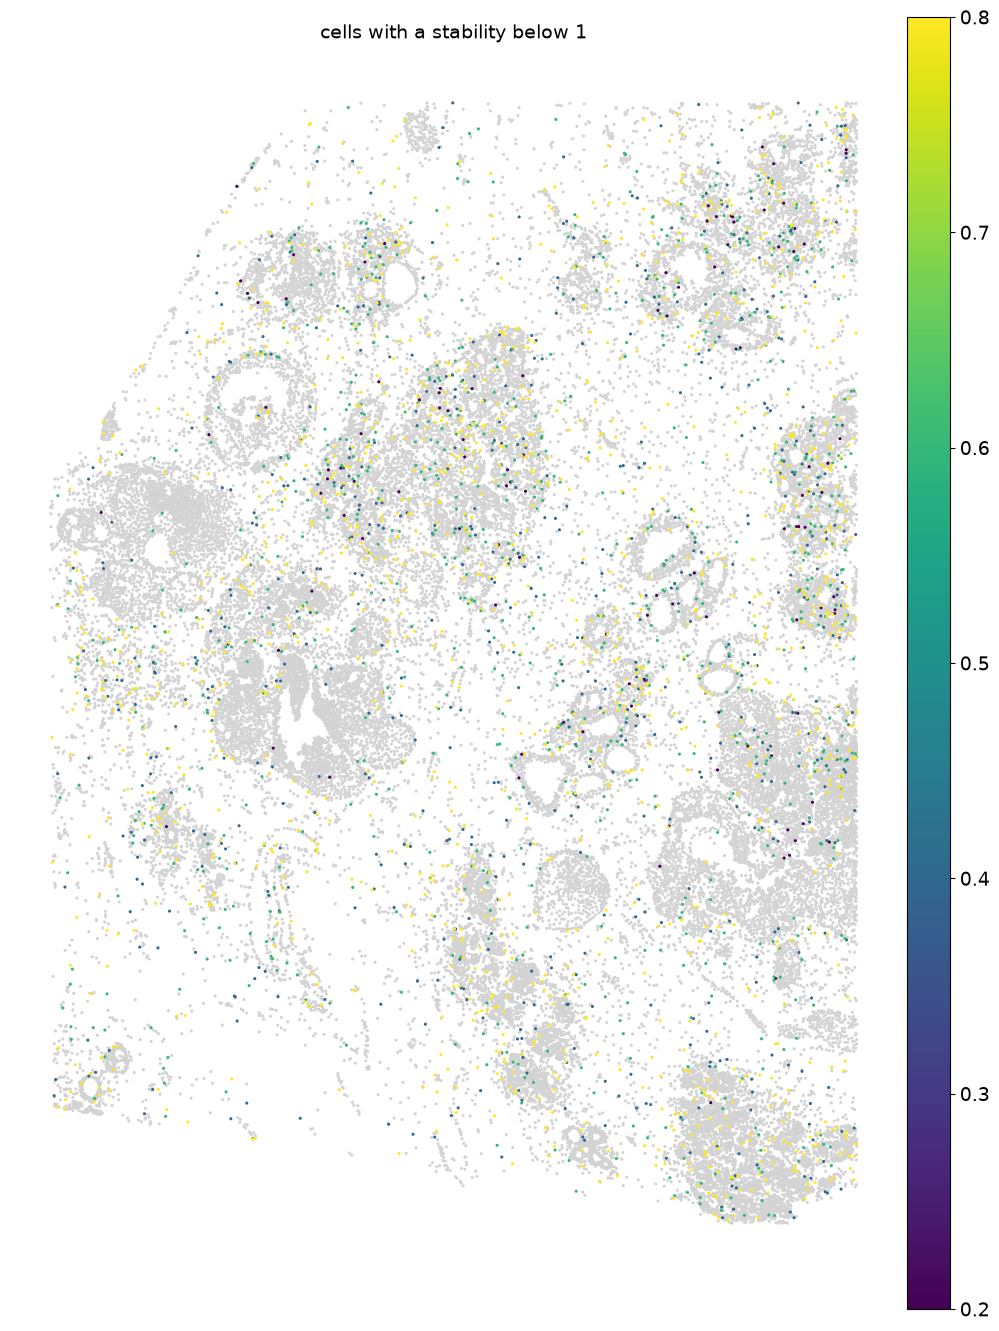

In [21]:
restarts = adata.uns["cn_none"]["restarts"]
print(f"fit kept: {restarts['chosen']}, aneuploid cells per fit: {restarts['n_aneuploid'].tolist()}")
print(pd.DataFrame(restarts["agreement"]).round(3).to_string())
stability = adata.obs["cn_none_stability"]
print(f"cells with a stability below 1: {(stability < 1).mean():.1%}")
print(stability[stability < 1].groupby(adata.obs["group"][stability < 1]).size().loc[lambda s: s > 0].to_string())
print(stability.value_counts().sort_index().to_string())
adata.obs["stability below 1"] = stability.where(stability < 1)
cnv.pl.spatial_cnv(adata, color="stability below 1", size=20, cmap="viridis", title="cells with a stability below 1")

Of its 5 fits, the run with seed 0 kept the last one (index 4). The fits make the same call for 95.5% to 98.7% of the
cells in each pair. `obs["cn_none_stability"]` is the share of the 5 fits that make the same call as the kept fit, so it
takes the values 0.2 to 1 in steps of 0.2 (with the default `key_added`, the column is `copy_number_stability`). Of all
cells, 6.7% have a stability below 1. Most of them are fibroblasts (1,063 cells) or smooth muscle cells and pericytes
(657), and few are in the epithelium of A, C or N. The map colors only the cells with a stability below 1. Treat their
calls as uncertain. The stability covers only the call, so a cell with a stability of 1 can still change its clone
between fits.

## Detectability

{func}`infercnvpy.tl.detectability` estimates how many cells a one-sided score test needs to detect the gain (1.5x) or
loss (0.5x) of a whole arm, when all the cells are of one type and carry the same change. It uses the counts of the
cells and the noise of the reference cells. The columns `cells_gain` and `cells_loss` hold these numbers of cells, and
the table gives their median over the arms, per type. The epithelial row holds the epithelial cells that aren't normal
epithelium.

In [22]:
cnv.tl.detectability(adata, groupby="cell_type_ref", reference_key="cell_type_ref", reference_cat=all_normal)
table = adata.uns["detectability"]["table"]
table.groupby("group", observed=True)[["cells_gain", "cells_loss"]].median().round(1)

,cells_gain,cells_loss
group,,
B/plasma,4.5,3.4
T/NK,6.0,4.6
endothelial,6.3,4.8
epithelial,3.7,2.8
fibroblast,7.8,6.0
myeloid,6.6,5.1
normal epithelium,5.0,3.8
smooth muscle/pericyte,5.6,4.2
unassigned,5.3,4.0


With the whole transcriptome, a test needs about 4 epithelial cells for the median arm to detect a gain and about 3 to
detect a loss. The numbers are for a test that knows the normal expression of each type. `tl.copy_number` and
`tl.infercnv` estimate it from the data, so they need more cells (see {func}`~infercnvpy.tl.detectability` and the
{doc}`Xenium tutorial <spatial_xenium>`). They also assume that expression follows the DNA copies one to one and that
the tumor is near diploid. In a near triploid tumor, one copy gained or lost is a ratio of 4/3 or 2/3, so pass
`gain=4/3` and `loss=2/3` and expect more cells. Compare the numbers with the size of the clones that you expect, to see
which arms your data can resolve.

## Summary

- Put every normal cell type that you can annotate into the reference, including stromal cells such as smooth muscle
  cells and pericytes, and normal epithelium. One way to choose them is to run `tl.copy_number` without a reference
  first, tabulate the aneuploid share per annotated type, and add the types that you know to be normal.
- Compare the calls per cell type with and without a reference. Many aneuploid calls in a normal type can mean that the
  type is missing from the reference, or that its cells are merged with tumor cells in the segmentation.
- Keep the default of 5 restarts and check the stability column. The clones change much more between fits than the
  calls.
- Pseudobulk profiles of regions with known copy number, as here from WGS, check the profiles of groups of cells, not
  the calls of single cells.
- Trust the results in this order, from most to least reliable. First, the calls of a run with every normal type in the
  reference. Second, losses of whole arms. Third, gains, which the pseudobulk shows only weakly here. Fourth, the split
  into clones, which changes between seeds. Last, narrow bands and the depth of single segments, which need DNA to
  confirm. A whole genome doubling stays invisible, and normal cells in a region dilute its pseudobulk.

In [23]:
# versions and threads used to run this notebook; INFERCNVPY_COMMIT is set by the script that ran it
print("infercnvpy", cnv.__version__, os.environ.get("INFERCNVPY_COMMIT", ""))
for package in ["anndata", "scanpy", "numpy", "pandas", "scipy", "scikit-learn", "numba"]:
    print(package, importlib.metadata.version(package))
print("numba threads", numba.get_num_threads(), "| CPUs", os.cpu_count())
print(f"run time of the notebook: {(time.perf_counter() - notebook_start) / 60:.0f} min")
try:
    import resource  # not on Windows

    scale = 1e9 if sys.platform == "darwin" else 1e6  # ru_maxrss is in bytes on macOS and in kB on Linux
    print(f"peak memory: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / scale:.1f} GB")
except ImportError:
    pass

infercnvpy 0.7.0rc2.dev6+g9bc2ac8 9bc2ac8
anndata 0.13.4
scanpy 1.12.6
numpy 2.5.5
pandas 3.1.1
scipy 1.18.1
scikit-learn 1.9.1
numba 0.68.1
numba threads 16 | CPUs 96
run time of the notebook: 10 min
peak memory: 6.6 GB
